In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelBinarizer, LabelEncoder, OrdinalEncoder, MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import roc_auc_score, mean_squared_error ,confusion_matrix, accuracy_score, classification_report, f1_score, precision_recall_fscore_support, precision_score, recall_score
from sklearn.svm import LinearSVC, SVC
from sklearn.kernel_approximation import Nystroem, RBFSampler
from sklearn.linear_model import SGDClassifier
from imblearn.under_sampling import RandomUnderSampler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.tree import plot_tree
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, GradientBoostingClassifier, AdaBoostClassifier, VotingClassifier, StackingClassifier
from xgboost import XGBClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

In [2]:
credit_df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML201EN-SkillsNetwork/labs/module_4/datasets/im_credit.csv", index_col=False)

In [3]:
credit_df.describe()

,V14,V17,V4,V10,V28,Class
count,200200.000000,200200.000000,200200.000000,200200.000000,200200.000000,200200.000000
mean,0.004525,0.006053,-0.007341,0.004126,-0.000307,0.000999
std,0.934493,0.804560,1.410574,1.069319,0.331857,0.031591
min,-18.493773,-21.906493,-5.683171,-23.228255,-15.430084,0.000000
25%,-0.422768,-0.482548,-0.855326,-0.535903,-0.053095,0.000000
50%,0.050951,-0.065741,-0.025630,-0.092073,0.011169,0.000000
75%,0.493254,0.399676,0.738444,0.454916,0.078333,0.000000
max,10.526766,9.253526,16.875344,23.745136,33.847808,1.000000


In [4]:
credit_df.head()

,V14,V17,V4,V10,V28,Class
0,0.423619,-0.210863,0.933459,0.027866,0.019308,0
1,0.986727,0.174009,-2.019905,-1.620065,-0.307753,0
2,-0.023094,-0.541985,-0.902618,-0.192212,-0.048965,0
3,-0.152111,-0.615094,1.276126,-0.026822,0.044480,0
4,-0.535807,-0.248563,4.517539,1.871441,0.120955,0


In [5]:
credit_df.columns

Index(['V14', 'V17', 'V4', 'V10', 'V28', 'Class'], dtype='str')

<Axes: xlabel='Class'>

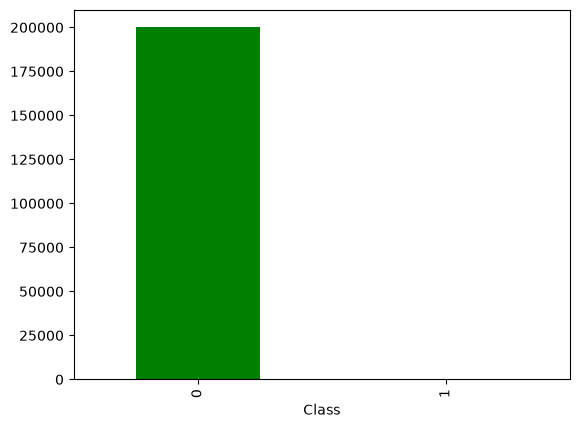

In [6]:
credit_df['Class'].value_counts().plot(kind="bar", color=['green', 'red'])

In [7]:
X= credit_df.drop("Class", axis=1)
y=credit_df['Class']

In [8]:
credit_df.isnull().sum()

V14      0
V17      0
V4       0
V10      0
V28      0
Class    0
dtype: int64

In [9]:
credit_df.skew()

V14      -1.537093
V17      -2.073488
V4        0.646426
V10       1.739818
V28      11.886778
Class    31.591391
dtype: float64

In [10]:
X.describe()

,V14,V17,V4,V10,V28
count,200200.000000,200200.000000,200200.000000,200200.000000,200200.000000
mean,0.004525,0.006053,-0.007341,0.004126,-0.000307
std,0.934493,0.804560,1.410574,1.069319,0.331857
min,-18.493773,-21.906493,-5.683171,-23.228255,-15.430084
25%,-0.422768,-0.482548,-0.855326,-0.535903,-0.053095
50%,0.050951,-0.065741,-0.025630,-0.092073,0.011169
75%,0.493254,0.399676,0.738444,0.454916,0.078333
max,10.526766,9.253526,16.875344,23.745136,33.847808


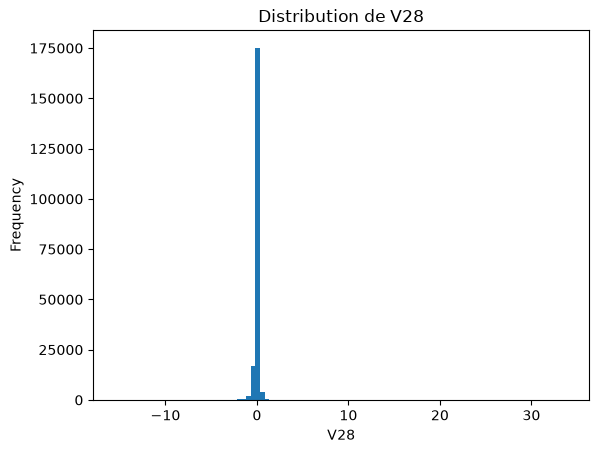

In [11]:
import matplotlib.pyplot as plt

plt.hist(X["V28"], bins=100)
plt.xlabel("V28")
plt.ylabel("Frequency")
plt.title("Distribution de V28")
plt.show()

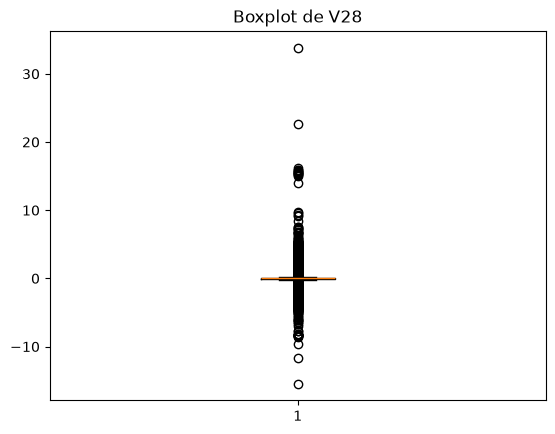

In [12]:
plt.boxplot(X["V28"])
plt.title("Boxplot de V28")
plt.show()

In [13]:
from sklearn.preprocessing import PowerTransformer

In [14]:
rs = 123
def evaluate(yt, yp, eval_type="Original"):
    results_pos = {}
    results_pos['type'] = eval_type
    # Accuracy
    results_pos['accuracy'] = accuracy_score(yt, yp)
    # Precision, recall, Fscore
    precision, recall, f_beta, _ = precision_recall_fscore_support(yt, yp, beta=5, pos_label=1, average='binary')
    results_pos['recall'] = recall
    # AUC
    results_pos['auc'] = roc_auc_score(yt, yp)
    # Precision
    results_pos['precision'] = precision
    # Fscore
    results_pos['fscore'] = f_beta
    return results_pos

In [15]:
def resample(X_train, y_train):
    # SMOTE sampler (Oversampling)
    smote_sampler = SMOTE(random_state = 123)
    # Undersampling
    under_sampler = RandomUnderSampler(random_state=123)
    # Resampled datasets
    X_smo, y_smo = smote_sampler.fit_resample(X_train, y_train)
    X_under, y_under = under_sampler.fit_resample(X_train, y_train)
    return X_smo, y_smo, X_under, y_under

In [16]:
X_train, X_test, y_train, y_test= train_test_split(X, y, random_state=42, stratify=y)

In [17]:
credit_df.dtypes

V14      float64
V17      float64
V4       float64
V10      float64
V28      float64
Class      int64
dtype: object

In [18]:
correlations=credit_df.corrwith(credit_df['Class'])
correlations.sort_values(ascending=False)

Class    1.000000
V4       0.102540
V28      0.003187
V10     -0.165271
V14     -0.238992
V17     -0.260135
dtype: float64

In [19]:
X_smo, y_smo, X_under, y_under=resample(X_train, y_train)

In [20]:
model1=make_pipeline(PowerTransformer(method="yeo-johnson"),
    LogisticRegression(l1_ratio=1, random_state=42, max_iter=1000, solver='saga'))
model1

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('powertransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"method method: {'yeo-johnson', 'box-cox'}, default='yeo-johnson'The power transform method. Available methods are:- 'yeo-johnson' [1]_, works with positive and negative values- 'box-cox' [2]_, only works with strictly positive values",'yeo-johnson'
,"standardize standardize: bool, default=TrueSet to True to apply zero-mean, unit-variance normalization to thetransformed output.",True
,"copy copy: bool, default=TrueSet to False to perform inplace computation during transformation.",True
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it ex

In [21]:
model1.fit(X_smo, y_smo)
y1_pred=model1.predict(X_test)

In [22]:
evaluate(y_test, y1_pred)

{'type': 'Original',
 'accuracy': 0.9607592407592408,
 'recall': 0.92,
 'auc': 0.9404,
 'precision': 0.022931206380857428,
 'fscore': 0.36732186732186733}

In [23]:
model3=make_pipeline(PowerTransformer(method="yeo-johnson"),
LogisticRegression(random_state=42, max_iter=2000))
model3.fit(X_under, y_under)
y3_pred=model3.predict(X_test)

In [24]:
evaluate(y_test, y3_pred)

{'type': 'Original',
 'accuracy': 0.952067932067932,
 'recall': 0.92,
 'auc': 0.9360499999999999,
 'precision': 0.018844735764031135,
 'fscore': 0.3240314277973449}

In [25]:
model2= make_pipeline(PowerTransformer(method="yeo-johnson"), 
RandomForestClassifier(random_state=42, n_estimators=100, max_depth=5, max_features=3))
model2

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('powertransformer', ...), ('randomforestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"method method: {'yeo-johnson', 'box-cox'}, default='yeo-johnson'The power transform method. Available methods are:- 'yeo-johnson' [1]_, works with positive and negative values- 'box-cox' [2]_, only works with strictly positive values",'yeo-johnson'
,"standardize standardize: bool, default=TrueSet to True to apply zero-mean, unit-variance normalization to thetransformed output.",True
,"copy copy: bool, default=TrueSet to False to perform inplace computation during transformation.",True
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100


In [26]:
model2.fit(X_smo, y_smo)
y2_pred=model2.predict(X_test)

In [27]:
evaluate(y_test, y2_pred)

{'type': 'Original',
 'accuracy': 0.9847552447552448,
 'recall': 0.9,
 'auc': 0.94242,
 'precision': 0.05603985056039851,
 'fscore': 0.5698977106673161}

In [28]:
model4=make_pipeline(PowerTransformer(method="yeo-johnson"),GradientBoostingClassifier(learning_rate=0.1, subsample=0.5, max_features=1, n_estimators=100))
model4

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('powertransformer', ...), ('gradientboostingclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"method method: {'yeo-johnson', 'box-cox'}, default='yeo-johnson'The power transform method. Available methods are:- 'yeo-johnson' [1]_, works with positive and negative values- 'box-cox' [2]_, only works with strictly positive values",'yeo-johnson'
,"standardize standardize: bool, default=TrueSet to True to apply zero-mean, unit-variance normalization to thetransformed output.",True
,"copy copy: bool, default=TrueSet to False to perform inplace computation during transformation.",True
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",0.5
,"max_features max_features: {'sqrt', 'log2'}, int or float, default=NoneThe number of features to consider when looking for the best split:- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0]` and the features considered at each split will be `max(1, int(max_features * n_features_in_))`.- If 'sqrt', then `max_features=sqrt(n_features)`.- If 'log2', then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Choosing `max_features < n_features` leads to a reduction of varianceand an increase in bias.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off b

In [29]:
model4.fit(X_smo, y_smo)
y4_pred=model4.predict(X_test)
evaluate(y_test, y4_pred)

{'type': 'Original',
 'accuracy': 0.9783416583416583,
 'recall': 0.92,
 'auc': 0.9492,
 'precision': 0.04085257548845471,
 'fscore': 0.5033670033670034}

In [30]:
model2.fit(X_under, y_under)
y2_pred=model2.predict(X_test)
evaluate(y_test, y2_pred)

{'type': 'Original',
 'accuracy': 0.9187612387612387,
 'recall': 0.98,
 'auc': 0.9493499999999999,
 'precision': 0.011910549343704424,
 'fscore': 0.23750932140193884}

In [31]:
model4.fit(X_under, y_under)
y4_pred=model4.predict(X_test)
evaluate(y_test, y4_pred)

{'type': 'Original',
 'accuracy': 0.9366433566433566,
 'recall': 0.98,
 'auc': 0.9583,
 'precision': 0.015222118670394533,
 'fscore': 0.28507496084135153}

In [32]:
class_weight = {}

# Assign weight of class 0 to be 0.1
class_weight[0] = 0.1

# Assign weight of class 1 to be 0.9
class_weight[1] = 0.9

In [33]:
model10=make_pipeline(PowerTransformer(method="yeo-johnson"),
    LogisticRegression(l1_ratio=1, random_state=42, max_iter=1000, solver='saga', class_weight=class_weight))

model10.fit(X_train, y_train)
y10_pred=model10.predict(X_test)
evaluate(y_test, y10_pred)

{'type': 'Original',
 'accuracy': 0.9994805194805195,
 'recall': 0.86,
 'auc': 0.9298099999999999,
 'precision': 0.6935483870967742,
 'fscore': 0.8521341463414634}

In [34]:
model12=make_pipeline(PowerTransformer(method="yeo-johnson"),
    RandomForestClassifier(random_state=42, n_estimators=100, max_depth=5, max_features=3, class_weight=class_weight))

model12.fit(X_train, y_train)
y12_pred=model12.predict(X_test)
evaluate(y_test, y12_pred)

{'type': 'Original',
 'accuracy': 0.9996003996003996,
 'recall': 0.88,
 'auc': 0.93986,
 'precision': 0.7586206896551724,
 'fscore': 0.8746177370030581}

In [35]:
model14=make_pipeline(PowerTransformer(method="yeo-johnson"), GradientBoostingClassifier(learning_rate=0.1, subsample=0.5, max_features=1, n_estimators=100))

model14.fit(X_train, y_train)
y14_pred=model14.predict(X_test)
evaluate(y_test, y14_pred)

{'type': 'Original',
 'accuracy': 0.9993406593406593,
 'recall': 0.6,
 'auc': 0.7998700000000001,
 'precision': 0.6976744186046512,
 'fscore': 0.6032482598607889}

In [ ]:
def grid_search_rf(X_train, y_train):
    params_grid = {
    'max_depth': [5, 10, 15, 20],
    'max_features': [1,2,3,4],
    'n_estimators': [25, 50, 100],
    'min_samples_split': [2, 5],
    'class_weight': [{0:0.1, 1:0.9}, {0:0.2, 1:0.8}, {0:0.3, 1:0.7}]
    }
    rf_model = RandomForestClassifier(random_state=42)
    grid_search = GridSearchCV(estimator = rf_model, 
                           param_grid = params_grid, 
                           scoring='f1',
                           cv = 5, verbose = 1)
    grid_search.fit(X_train, y_train)
    best_params = grid_search.best_estimator_
    return best_params

In [ ]:
model_final=grid_search_rf(X_train, y_train)

In [ ]:
model=make_pipeline(PowerTransformer(method="yeo-johnson"), 
                    model_final)

model.fit(X_train, y_train)
y_pred=model14.predict(X_test)
evaluate(y_test, y_pred)

In [36]:
from lime import lime_tabular

explainer = lime_tabular.LimeTabularExplainer(
    training_data=X_test.values,
    mode='classification',
    class_names = ['Not Changing', 'Changing'],
    feature_names=list(X_train.columns),
    random_state=123,
    verbose=True)

In [37]:
instance_index = 19
selected_instance = X_test.iloc[[instance_index]]
lime_test_instance = selected_instance.values.reshape(-1)
selected_instance

,V14,V17,V4,V10,V28
196623,1.512959,0.653437,-3.124908,-1.891037,0.140494


C:\Users\hp\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(


Intercept 0.002163285605805149
Prediction_local [0.00132283]
Right: 0.000931385369258205


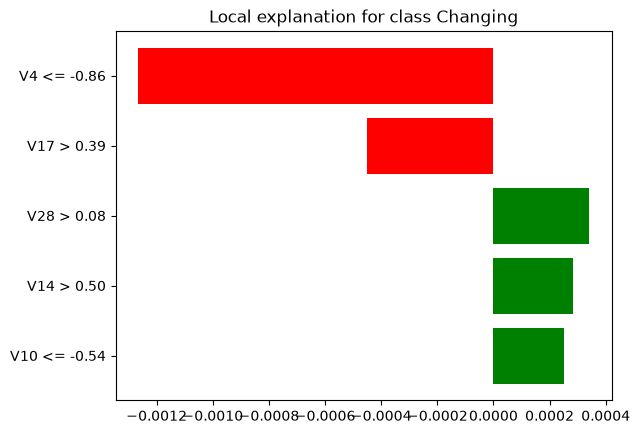

In [39]:
exp = explainer.explain_instance(
                                 # Instance to explain
                                 lime_test_instance, 
                                 # The prediction from black-box model
                                 model12.predict_proba,
                                 # Use max 10 features
                                 num_features=10)
exp.as_pyplot_figure();